# 02 · Portfolio analysis: what 1,825 real headline tests say about A/B testing

Notebook 01 analysed one test. A product team runs hundreds, and the questions change at that scale:

1. **Can we trust the randomizer?** A sample-ratio-mismatch audit across 4,873 tests.
2. **Are our p-values calibrated?** The archive contains hundreds of *near A/A tests* (identical headline and image in every arm). We use them to measure the real false-positive rate of a naive z-test.
3. **How many "winners" survive multiple-comparison correction**, within a test and across the portfolio?
4. **How big are true headline effects**, net of noise (random-effects meta-analysis)?
5. **Were these tests powered** to detect effects of that size?
6. **Winner's curse:** how much should an observed winning lift be shrunk (empirical Bayes)?
7. **Frequentist vs Bayesian decisions** across the portfolio.
8. **Did Upworthy's dashboard crown real winners?**

All analysis uses the archive's **exploratory** sample. The confirmatory sample is reserved for notebook 04, and the holdout sample is never touched.

In [1]:
import sys, json
sys.path.insert(0, "../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy import stats
from statsmodels.stats.multitest import multipletests

from abtest import data, frequentist as fq, power, bayesian as bayes, meta, plotting as P

P.apply_style()
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
RESULTS = {}

df = data.load_packages("exploratory")
summ = data.test_summary(df)
print(f"{len(df):,} packages in {summ.shape[0]:,} tests, {df.created_at.min():%b %Y} – {df.created_at.max():%b %Y}")
pd.crosstab(summ["kind"], summ["problem"].map({False: "outside problem window", True: "inside problem window"}), margins=True)

22,666 packages in 4,873 tests, Jan 2013 – Apr 2015


problem,inside problem window,outside problem window,All
kind,,,
both,65,235,300
headline,482,1825,2307
image,310,1116,1426
same_stim,193,647,840
All,1050,3823,4873


## 1 · Randomization audit: sample-ratio mismatch over time

Upworthy meant to split traffic evenly across arms. A chi-square goodness-of-fit test on each test's impressions flags a **sample-ratio mismatch (SRM)** at p < 0.001. The archive's maintainers later reported a randomization bug affecting tests from 25 June 2013 to 10 January 2014. If SRM is a useful guardrail, it should find that window without being told about it.

SRM failure rate: inside window 70.0%, outside 0.47%


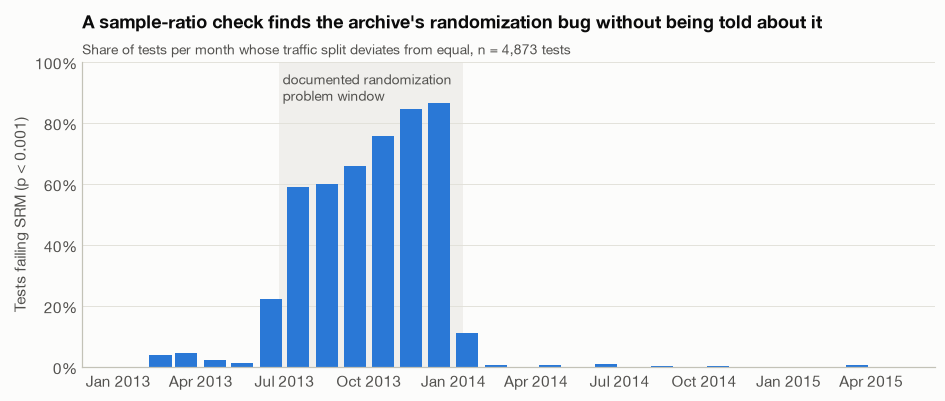

In [2]:
summ["srm_fail"] = summ["srm_p"] < 0.001
summ["month"] = summ["created_at"].dt.to_period("M").dt.to_timestamp()
monthly = summ.groupby("month").agg(tests=("test_id", "size"), srm_fail=("srm_fail", "mean")).reset_index()

by_window = summ.groupby("problem")["srm_fail"].mean()
print(f"SRM failure rate: inside window {by_window[True]:.1%}, outside {by_window[False]:.2%}")
RESULTS["srm_fail_inside"] = by_window[True]
RESULTS["srm_fail_outside"] = by_window[False]

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.axvspan(data.PROBLEM_START, data.PROBLEM_END, color=P.NEUTRAL, zorder=0, lw=0)
ax.text(data.PROBLEM_START + pd.Timedelta(days=4), 0.97, "documented randomization\nproblem window",
        color=P.INK_2, fontsize=9, va="top")
ax.bar(monthly["month"] + pd.Timedelta(days=15), monthly["srm_fail"], width=24, color=P.BLUE)
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.set_ylabel("Tests failing SRM (p < 0.001)")
ax.grid(axis="x", visible=False)
ax.set_title("A sample-ratio check finds the archive's randomization bug without being told about it")
P.subtitle(ax, f"Share of tests per month whose traffic split deviates from equal, n = {len(summ):,} tests")
P.save(fig, "05_srm_audit")
plt.show()

Everything from here on **excludes the problem window**, which is what the archive's maintainers recommend.

## 2 · Are naive p-values calibrated? Evidence from near A/A tests

In 647 tests every arm showed the *same headline and the same image*. According to the archive documentation, the fields that did differ (excerpt, share text) were not shown in the test, so these are the closest thing the archive has to **A/A tests**. If each impression were an independent Bernoulli trial, only 5% of arm-vs-first-arm comparisons should come out significant at α = 0.05.

In [3]:
aa = data.vs_control(data.package_arms(df, "same_stim"))
hl_arms = data.headline_arms(df)
hl = data.vs_control(hl_arms)

for frame in (aa, hl):
    frame["z"], frame["p"] = fq.two_proportion_ztest(frame["clicks"], frame["impressions"],
                                                     frame["clicks_c"], frame["impressions_c"])
    frame["log_or"], frame["se"] = meta.log_odds_ratio(frame["clicks"], frame["impressions"],
                                                       frame["clicks_c"], frame["impressions_c"])
aa = aa[np.isfinite(aa["z"])]

fp_aa, sig_hl = (aa["p"] < 0.05).mean(), (hl["p"] < 0.05).mean()
print(f"Near A/A comparisons: {len(aa):,} from {aa.test_id.nunique()} tests -> {fp_aa:.1%} significant at 0.05 (expected 5%)")
print(f"Headline comparisons: {len(hl):,} from {hl.test_id.nunique()} tests -> {sig_hl:.1%} significant at 0.05")

# If z ~ N(0, phi) under the null, phi is the variance inflation. Use a robust (MAD) estimate.
phi = (np.median(np.abs(aa["z"])) / stats.norm.ppf(0.75)) ** 2
phi_var = aa["z"].var()
print(f"Variance inflation of z under the null: phi = {phi:.2f} (robust), {phi_var:.2f} (plain variance)")

aa["p_cal"] = 2 * stats.norm.sf(np.abs(aa["z"]) / np.sqrt(phi))
hl["p_cal"] = 2 * stats.norm.sf(np.abs(hl["z"]) / np.sqrt(phi))
print(f"After calibration: near A/A {(aa['p_cal'] < 0.05).mean():.1%} significant, headline {(hl['p_cal'] < 0.05).mean():.1%}")
RESULTS.update(n_aa=len(aa), fp_aa=fp_aa, sig_hl_naive=sig_hl, phi=phi,
               fp_aa_cal=(aa["p_cal"] < 0.05).mean(), sig_hl_cal=(hl["p_cal"] < 0.05).mean(),
               n_headline_tests=int(hl.test_id.nunique()), n_headline_comparisons=len(hl))

Near A/A comparisons: 2,418 from 646 tests -> 12.8% significant at 0.05 (expected 5%)
Headline comparisons: 6,529 from 1825 tests -> 28.7% significant at 0.05
Variance inflation of z under the null: phi = 1.67 (robust), 1.74 (plain variance)
After calibration: near A/A 5.4% significant, headline 17.4%


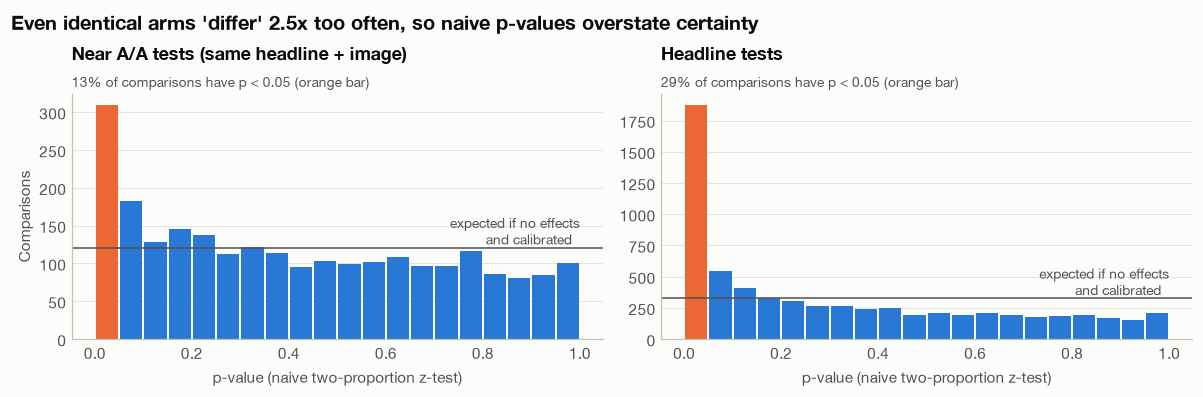

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=False)
bins = np.linspace(0, 1, 21)
for ax, frame, name, share in [(axes[0], aa, "Near A/A tests (same headline + image)", fp_aa),
                               (axes[1], hl, "Headline tests", sig_hl)]:
    counts, _, bars = ax.hist(frame["p"], bins=bins, color=P.BLUE, rwidth=0.92)
    bars[0].set_color(P.ORANGE)
    ax.axhline(len(frame) / 20, color=P.INK_2, lw=1)
    ax.text(1, len(frame) / 20, "expected if no effects\nand calibrated  ", ha="right", va="bottom",
            color=P.INK_2, fontsize=9)
    ax.set_xlabel("p-value (naive two-proportion z-test)")
    ax.grid(axis="x", visible=False)
    ax.set_title(name)
    P.subtitle(ax, f"{share:.0%} of comparisons have p < 0.05 (orange bar)")
axes[0].set_ylabel("Comparisons")
fig.tight_layout()
fig.subplots_adjust(top=0.78)
fig.suptitle("Even identical arms 'differ' 2.5x too often, so naive p-values overstate certainty",
             x=0.01, ha="left", fontsize=13, fontweight="bold", y=0.99)
P.save(fig, "06_pvalue_calibration")
plt.show()

**What this means.** Under the null the z-statistic is about √φ times wider than a binomial model assumes. Possible causes are repeat impressions from the same visitor, time-of-day traffic mix, or unlogged stimulus differences. Whatever the cause, the practical rule is the same: **run A/A tests and calibrate your test statistic before trusting it.** From here on we report both naive and A/A-calibrated results (z / √φ). Because the near-A/A arms may still have differed slightly, the calibration is, if anything, conservative.

## 3 · How many winners survive correction?

Each headline test compares several challengers with the same control, so each test is a family of comparisons. A team running 1,825 tests is also making about 6,500 decisions. We count significant comparisons under:

- no correction
- Holm and Benjamini–Hochberg **within each test** (controls errors per experiment)
- Benjamini–Hochberg **across the whole portfolio** (controls the share of false discoveries among everything the team ships)

In [5]:
def within_test(frame, pcol, method):
    return frame.groupby("test_id")[pcol].transform(lambda s: multipletests(s, method=method)[0]).astype(bool)

rows = []
for label, pcol in [("Naive", "p"), ("A/A-calibrated", "p_cal")]:
    rules = {
        "No correction": hl[pcol] < 0.05,
        "Holm (within test)": within_test(hl, pcol, "holm"),
        "BH (within test)": within_test(hl, pcol, "fdr_bh"),
        "BH (portfolio-wide)": pd.Series(multipletests(hl[pcol], method="fdr_bh")[0], index=hl.index),
    }
    for rule, sig in rules.items():
        rows.append({"p-values": label, "rule": rule, "significant": int(sig.sum()),
                     "challenger better": int((sig & (hl["z"] > 0)).sum()),
                     "challenger worse": int((sig & (hl["z"] < 0)).sum())})
        if label == "A/A-calibrated" and rule == "Holm (within test)":
            hl["win_holm_cal"] = sig & (hl["z"] > 0)
disc = pd.DataFrame(rows)
RESULTS["discoveries"] = disc.to_dict(orient="records")
disc

,p-values,rule,significant,challenger better,challenger worse
0,Naive,No correction,1872,690,1182
1,Naive,Holm (within test),1293,481,812
2,Naive,BH (within test),1429,519,910
3,Naive,BH (portfolio-wide),1032,378,654
4,A/A-calibrated,No correction,1136,416,720
5,A/A-calibrated,Holm (within test),686,230,456
6,A/A-calibrated,BH (within test),753,255,498
7,A/A-calibrated,BH (portfolio-wide),268,83,185


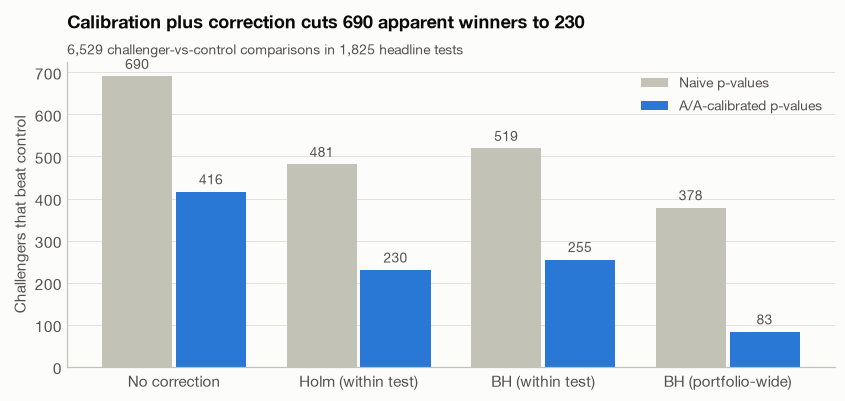

In [6]:
piv = disc.pivot(index="rule", columns="p-values", values="challenger better").loc[[r for r in disc["rule"].unique()]]
x = np.arange(len(piv))
fig, ax = plt.subplots(figsize=(9, 3.6))
w = 0.38
for j, (col, color) in enumerate([("Naive", P.CONTEXT), ("A/A-calibrated", P.BLUE)]):
    b = ax.bar(x + (j - 0.5) * (w + 0.02), piv[col], width=w, color=color, label=col + " p-values")
    ax.bar_label(b, fmt="{:,.0f}", padding=3, color=P.INK_2, fontsize=9)
ax.set_xticks(x, piv.index)
ax.set_ylabel("Challengers that beat control")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper right")
ax.set_title(f"Calibration plus correction cuts {piv.loc['No correction', 'Naive']:,} apparent winners "
             f"to {piv.loc['Holm (within test)', 'A/A-calibrated']:,}")
P.subtitle(ax, f"{len(hl):,} challenger-vs-control comparisons in {hl.test_id.nunique():,} headline tests")
P.save(fig, "07_discoveries")
plt.show()

## 4 · How large are true headline effects?

Observed lifts mix two things: real differences between headlines and sampling noise. A **random-effects (DerSimonian–Laird) meta-analysis** on the log odds ratio separates them. It estimates τ, the standard deviation of *true* effects across comparisons. Running the same analysis on the near A/A comparisons gives the "noise floor" τ that appears even when nothing changes, and subtracting it in variance gives a net estimate for headlines.

In [7]:
mu_hl, tau2_hl = meta.dersimonian_laird(hl["log_or"], hl["se"])
mu_aa, tau2_aa = meta.dersimonian_laird(aa["log_or"], aa["se"])
tau2_net = max(tau2_hl - tau2_aa, 0)
tau_net = np.sqrt(tau2_net)
print(f"Headline comparisons: mean log OR {mu_hl:+.3f} ({np.expm1(mu_hl):+.1%}), tau = {np.sqrt(tau2_hl):.3f}")
print(f"Near A/A comparisons: mean log OR {mu_aa:+.3f} ({np.expm1(mu_aa):+.1%}), tau = {np.sqrt(tau2_aa):.3f}")
print(f"Net SD of true headline effects: tau = {tau_net:.3f} -> a 1-SD better headline lifts CTR by ~{np.expm1(tau_net):.0%}")
share_10 = 2 * stats.norm.sf(np.log(1.10), loc=0, scale=tau_net)
print(f"Implied share of challengers whose true effect is beyond ±10%: {share_10:.0%}")
RESULTS.update(mu_hl=mu_hl, tau_hl=np.sqrt(tau2_hl), mu_aa=mu_aa, tau_aa=np.sqrt(tau2_aa), tau_net=tau_net,
               lift_1sd=np.expm1(tau_net))

Headline comparisons: mean log OR -0.078 (-7.5%), tau = 0.360
Near A/A comparisons: mean log OR -0.005 (-0.5%), tau = 0.159
Net SD of true headline effects: tau = 0.323 -> a 1-SD better headline lifts CTR by ~38%
Implied share of challengers whose true effect is beyond ±10%: 77%


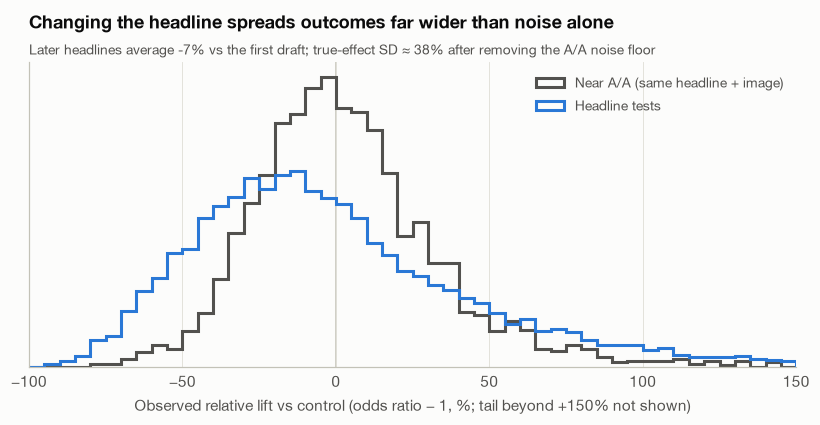

In [8]:
fig, ax = plt.subplots(figsize=(9, 3.6))
bins = np.linspace(-150, 150, 61)
for frame, name, color in [(aa, "Near A/A (same headline + image)", P.INK_2), (hl, "Headline tests", P.BLUE)]:
    ax.hist(np.expm1(frame["log_or"]) * 100, bins=bins, density=True, histtype="step",
            lw=2, color=color, label=name)
ax.axvline(0, color=P.AXIS, lw=1, zorder=0)
ax.set_xlim(-100, 150)
ax.set_xlabel("Observed relative lift vs control (odds ratio − 1, %; tail beyond +150% not shown)")
ax.set_yticks([])
ax.grid(axis="y", visible=False)
ax.legend(loc="upper right")
ax.set_title("Changing the headline spreads outcomes far wider than noise alone")
P.subtitle(ax, f"Later headlines average {np.expm1(mu_hl):+.0%} vs the first draft; true-effect SD ≈ {np.expm1(tau_net):.0%} after removing the A/A noise floor")
P.save(fig, "08_effect_distribution")
plt.show()

## 5 · Were these tests powered?

For each test we compute the minimum detectable relative lift (80% power, α = 0.05, two-sided) from its own baseline CTR and impressions per arm. We then compare it with the effect sizes that actually occur. This is the *naive* MDE. Using the A/A variance inflation would make it worse.

In [9]:
per_test = (hl_arms.groupby("test_id")
            .agg(n_arm=("impressions", "mean"), n_arms=("arm", "size"))
            .join(hl_arms.loc[hl_arms["is_control"]].set_index("test_id")["ctr"].rename("ctr_c")))
per_test = per_test[per_test["ctr_c"] > 0]
per_test["mde"] = [power.mde(p, n) for p, n in zip(per_test["ctr_c"], per_test["n_arm"])]
per_test["power_1sd"] = [power.power_at(p, np.expm1(tau_net), n) for p, n in zip(per_test["ctr_c"], per_test["n_arm"])]
per_test["power_10"] = [power.power_at(p, 0.10, n) for p, n in zip(per_test["ctr_c"], per_test["n_arm"])]

print(f"Median impressions per arm {per_test.n_arm.median():,.0f}, median control CTR {per_test.ctr_c.median():.2%}")
print(f"Median MDE: {per_test.mde.median():+.0%} relative lift")
print(f"Share of tests with >= 80% power for a 1-SD true effect ({np.expm1(tau_net):+.0%}): {(per_test.power_1sd >= 0.8).mean():.1%}")
print(f"Median power for a +10% lift: {per_test.power_10.median():.1%}")
RESULTS.update(median_n_arm=per_test.n_arm.median(), median_ctr_c=per_test.ctr_c.median(),
               median_mde=per_test.mde.median(), share_powered_1sd=(per_test.power_1sd >= 0.8).mean(),
               median_power_10=per_test.power_10.median(), median_power_1sd=per_test.power_1sd.median())

Median impressions per arm 3,223, median control CTR 1.04%
Median MDE: +77% relative lift
Share of tests with >= 80% power for a 1-SD true effect (+38%): 5.3%
Median power for a +10% lift: 7.0%


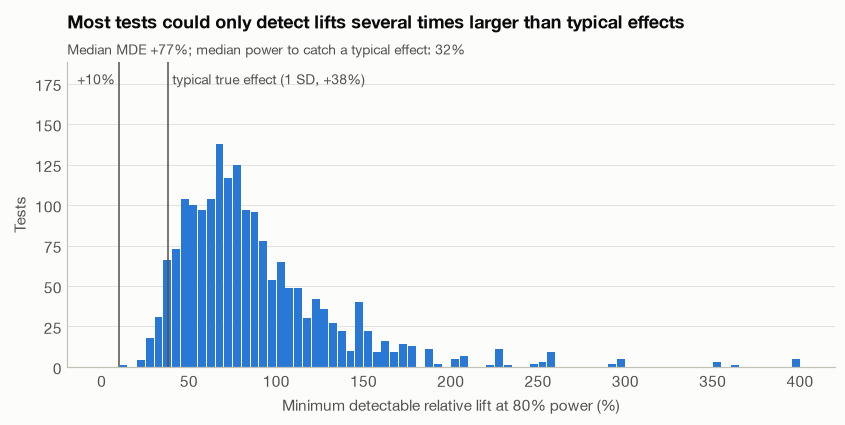

In [10]:
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.hist(np.clip(per_test["mde"] * 100, 0, 400), bins=np.linspace(0, 400, 81), color=P.BLUE, rwidth=0.9)
ymax = ax.get_ylim()[1] * 1.3
ax.set_ylim(0, ymax)
for v, lab, ha in [(10, "+10% ", "right"), (np.expm1(tau_net) * 100, f" typical true effect (1 SD, +{np.expm1(tau_net):.0%})", "left")]:
    ax.axvline(v, color=P.INK_2, lw=1)
    ax.text(v, ymax * 0.97, lab, color=P.INK_2, fontsize=9, va="top", ha=ha)
ax.set_xlabel("Minimum detectable relative lift at 80% power (%)")
ax.set_ylabel("Tests")
ax.grid(axis="x", visible=False)
ax.set_title("Most tests could only detect lifts several times larger than typical effects")
P.subtitle(ax, f"Median MDE {per_test.mde.median():+.0%}; median power to catch a typical effect: {per_test.power_1sd.median():.0%}")
P.save(fig, "09_power_mde")
plt.show()

## 6 · Winner's curse: shrink the winners

When tests are underpowered, the comparisons that clear significance are the ones where noise happened to push the estimate up, so **observed winning lifts are inflated**. Empirical Bayes fixes this by using the portfolio as a prior. Each comparison's log odds ratio is shrunk toward the portfolio mean, and noisier estimates are shrunk more:

$$\hat\theta_i^{EB} = \mu + \frac{\tau^2}{\tau^2 + \phi\, se_i^2}(y_i - \mu)$$

We apply this to the **best-performing challenger in every test**, which is exactly the number a team would announce.

In [11]:
hl["se_cal"] = hl["se"] * np.sqrt(phi)
hl["eb_mean"], hl["eb_sd"] = meta.shrink(hl["log_or"], hl["se_cal"], mu_hl, tau2_net)
best = hl.loc[hl.groupby("test_id")["ctr"].idxmax()].copy()
best["obs_lift"], best["eb_lift"] = np.expm1(best["log_or"]), np.expm1(best["eb_mean"])

sig_best = best[best["win_holm_cal"]]
print(f"Best challenger per test (n = {len(best):,}): median observed lift {best.obs_lift.median():+.1%}, after shrinkage {best.eb_lift.median():+.1%}")
print(f"Calibrated-Holm winners (n = {len(sig_best)}): median observed lift {sig_best.obs_lift.median():+.1%}, after shrinkage {sig_best.eb_lift.median():+.1%}")
RESULTS.update(best_obs_median=best.obs_lift.median(), best_eb_median=best.eb_lift.median(),
               winners_obs_median=sig_best.obs_lift.median(), winners_eb_median=sig_best.eb_lift.median(),
               n_winners_holm_cal=len(sig_best))

Best challenger per test (n = 1,825): median observed lift +20.1%, after shrinkage +6.7%
Calibrated-Holm winners (n = 166): median observed lift +148.7%, after shrinkage +49.1%


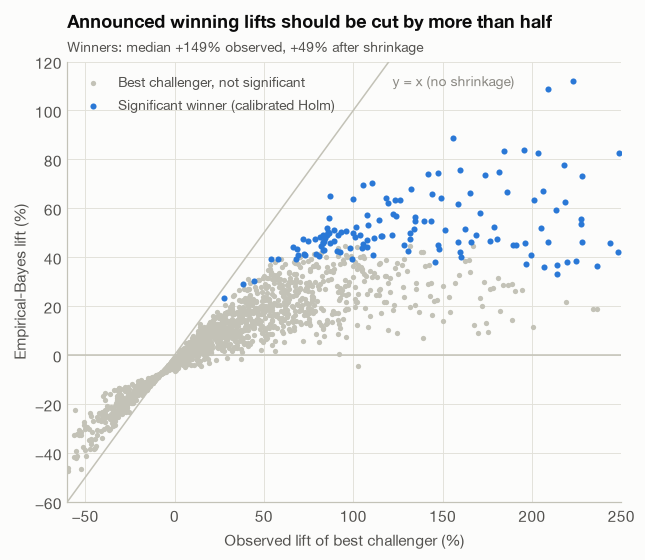

In [12]:
fig, ax = plt.subplots(figsize=(6.5, 5.2))
lim = (-60, 250)
ax.plot(lim, lim, color=P.AXIS, lw=1, zorder=1)
ax.text(122, 112, "y = x (no shrinkage)", color=P.MUTED, fontsize=9, va="center")
ax.axhline(0, color=P.AXIS, lw=1, zorder=1)
other = best[~best["win_holm_cal"]]
ax.scatter(other.obs_lift * 100, other.eb_lift * 100, s=12, color=P.CONTEXT, lw=0, label="Best challenger, not significant")
ax.scatter(sig_best.obs_lift * 100, sig_best.eb_lift * 100, s=16, color=P.BLUE, lw=0, label="Significant winner (calibrated Holm)")
ax.set_xlim(*lim)
ax.set_ylim(-60, 120)
ax.set_xlabel("Observed lift of best challenger (%)")
ax.set_ylabel("Empirical-Bayes lift (%)")
ax.legend(loc="upper left")
ax.set_title("Announced winning lifts should be cut by more than half")
P.subtitle(ax, f"Winners: median {sig_best.obs_lift.median():+.0%} observed, {sig_best.eb_lift.median():+.0%} after shrinkage")
P.save(fig, "10_winners_curse_shrinkage")
plt.show()

## 7 · Frequentist vs Bayesian decisions across the portfolio

For each test, should the best challenger replace the control? Four rules:

| Rule | Ship if |
|---|---|
| Naive Holm | best challenger beats control, Holm-adjusted naive p < 0.05 |
| Calibrated Holm | same, with A/A-calibrated p-values |
| Bayesian, flat prior | P(best challenger > control) > 95% from independent Beta(1,1) posteriors |
| Bayesian, hierarchical | P(true lift > 0) > 95% under the empirical-Bayes posterior (portfolio prior + calibrated noise) |

In [13]:
naive_holm = within_test(hl, "p", "holm") & (hl["z"] > 0)
best["ship_naive_holm"] = naive_holm.loc[best.index]
best["ship_cal_holm"] = best["win_holm_cal"]
best["p_flat"] = bayes.prob_beats_normal(best["clicks"], best["impressions"], best["clicks_c"], best["impressions_c"])
best["ship_bayes_flat"] = best["p_flat"] > 0.95
best["p_eb"] = stats.norm.cdf(best["eb_mean"] / best["eb_sd"])
best["ship_bayes_eb"] = best["p_eb"] > 0.95

rules = {"Naive Holm": "ship_naive_holm", "Calibrated Holm": "ship_cal_holm",
         "Bayesian, flat prior": "ship_bayes_flat", "Bayesian, hierarchical": "ship_bayes_eb"}
ship = pd.DataFrame({"tests shipping a challenger": {k: int(best[v].sum()) for k, v in rules.items()},
                     "share of tests": {k: best[v].mean() for k, v in rules.items()}})
RESULTS["ship_rules"] = ship.to_dict()
print(ship)
print("\nAgreement: calibrated Holm vs hierarchical Bayes")
pd.crosstab(best["ship_cal_holm"], best["ship_bayes_eb"], rownames=["Calibrated Holm"], colnames=["Hierarchical Bayes"])

                        tests shipping a challenger  share of tests
Naive Holm                                      330          0.1808
Calibrated Holm                                 166          0.0910
Bayesian, flat prior                            552          0.3025
Bayesian, hierarchical                          153          0.0838

Agreement: calibrated Holm vs hierarchical Bayes


Hierarchical Bayes,False,True
Calibrated Holm,,
False,1629,30
True,43,123


**The key point.** A flat-prior Bayesian rule ("ship when P(B > A) > 95%") gives no protection against multiple comparisons or poor calibration. Applied to the best of several challengers, it ships the most. The Bayesian approach only becomes more conservative when the prior carries real information, here a portfolio-level prior that knows most headline changes are small. Being Bayesian does not by itself protect you from false winners. An honest prior does.

## 8 · Did Upworthy's dashboard crown real winners?

Every test in the archive has a `first_place` package, the leader shown in Upworthy's internal dashboard. How often is that leader statistically distinguishable from the runner-up?

In [14]:
rows = []
for tid, x in hl_arms.groupby("test_id"):
    if x["first_place"].sum() != 1:
        continue
    lead = x[x["first_place"]].iloc[0]
    runner = x[~x["first_place"]].sort_values("ctr", ascending=False).iloc[0]
    z, p = fq.two_proportion_ztest(lead.clicks, lead.impressions, runner.clicks, runner.impressions)
    rows.append({"test_id": tid, "leader_is_max": lead.ctr >= x.ctr.max(), "z": z,
                 "p": p, "p_cal": 2 * stats.norm.sf(abs(z) / np.sqrt(phi))})
lead = pd.DataFrame(rows)
print(f"Tests with a single dashboard leader: {len(lead):,}")
print(f"Leader has the highest observed CTR: {lead.leader_is_max.mean():.1%}")
print(f"Leader significantly better than runner-up: naive {(lead.p < 0.05).mean():.1%}, calibrated {(lead.p_cal < 0.05).mean():.1%}")
RESULTS.update(leader_sig_naive=(lead.p < 0.05).mean(), leader_sig_cal=(lead.p_cal < 0.05).mean(),
               leader_is_max=lead.leader_is_max.mean())

Tests with a single dashboard leader: 1,813
Leader has the highest observed CTR: 88.1%
Leader significantly better than runner-up: naive 13.7%, calibrated 7.1%


In [15]:
hl.to_csv("../reports/results/02_headline_comparisons.csv", index=False)
best.to_csv("../reports/results/02_best_challenger_per_test.csv", index=False)
with open("../reports/results/02_portfolio.json", "w") as f:
    json.dump(RESULTS, f, indent=2, default=float)